# 05b: CNN-BiLSTM-Attention v2 (log-scaled inputs + port embedding)

Notebook 05 left the proposed network about 0.09 macro-F1 behind XGBoost, and two architecture variants did not change that. This notebook records the actual cause and the fix.

**Diagnosis.** Reading how the inputs were prepared: max-impute, then a plain standard scaler, with no log transform. Features such as `Flow Bytes/s` reach about 1e9, so a few huge values dominate the scaled inputs, which hurts a neural network far more than a tree model. Ports were also scaled as if they were magnitudes, although they are service names (the SHAP analysis in notebook 08 shows Source Port is XGBoost's most influential feature).

**Controlled test** (`experiments/nn_inputs.py`): the same 25% sample of training rows, group split, full test set, same class weights and early stopping; one change at a time.

**Fix (v2).** `src/preprocessing/neural.py` applies a signed log1p before scaling and also supplies two port buckets (exact below 1024, coarse above) that `build_cnn_bilstm_attention(port_embedding=True)` embeds and concatenates after the attention pooling. Training code: `src/training/hybrid_v2.py`, run on the full data for both splits.

In [1]:
import json, sys
from pathlib import Path
sys.path.append(str(Path("..").resolve()))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from src.evaluation.metrics import evaluate, plot_confusion

REPORTS, FIGS = Path("../reports"), Path("../reports/figures")
encoding = json.load(open(REPORTS / "label_encoding.json"))
class_names = sorted(encoding, key=encoding.get)
sns.set_theme(style="whitegrid")

## The controlled experiment
Each row changes one thing against the control, on the same 25% training sample.

In [2]:
pd.read_csv(REPORTS / "nn_inputs_experiment.csv")

,variant,macro_f1,accuracy,epochs,minutes
0,control,0.6655,0.6999,8,14.8
1,log,0.7385,0.7515,13,24.4
2,ports,0.7246,0.7488,14,31.3
3,log+ports,0.7605,0.7713,15,30.9


## Full-data results
Trained on all group-split and random-split training rows (the 25% sample above was only for the controlled test).

In [3]:
v2 = pd.read_csv(REPORTS / "hybrid_v2_results.csv")
v1 = pd.read_csv(REPORTS / "hybrid_results.csv").assign(model="CNN-BiLSTM-Attention (un-pooled, v1)")
xgb = pd.read_csv(REPORTS / "baseline_results.csv").query("model == 'XGBoost'").rename(columns={"protocol": "split"})
cols = ["split", "model", "macro_f1", "accuracy"]
comparison = pd.concat([xgb[cols], v1[cols], v2[cols]], ignore_index=True)
comparison.to_csv(REPORTS / "hybrid_v1_v2_comparison.csv", index=False)
comparison.pivot(index="model", columns="split", values=["macro_f1", "accuracy"]).round(4)

macro_f1         accuracy        
split                                   group  random    group  random
model                                                                 
CNN-BiLSTM-Attention (log + ports)     0.7443  0.7701   0.7682  0.7667
CNN-BiLSTM-Attention (un-pooled, v1)   0.6900  0.7050   0.7183  0.7135
XGBoost                                0.7828  0.7907   0.8016  0.7870

## A tuned decision rule
Per-class log-probability offsets, fitted for macro-F1 on the validation slice that early stopping already used (a stratified 10% of the training rows), then applied to the test set. The test rows never influence them. The same rule is applied by the served model (`offsets_hybrid13_group.json`).

In [4]:
pd.read_csv(REPORTS / "hybrid_v2_offsets_results.csv")

,split,val_macro_f1_tuned,test_macro_f1_raw,test_accuracy_raw,test_macro_f1_offsets,test_accuracy_offsets
0,group,0.7804,0.7443,0.7682,0.7476,0.7742
1,random,0.7772,0.7701,0.7667,0.7772,0.7752


## Training curves

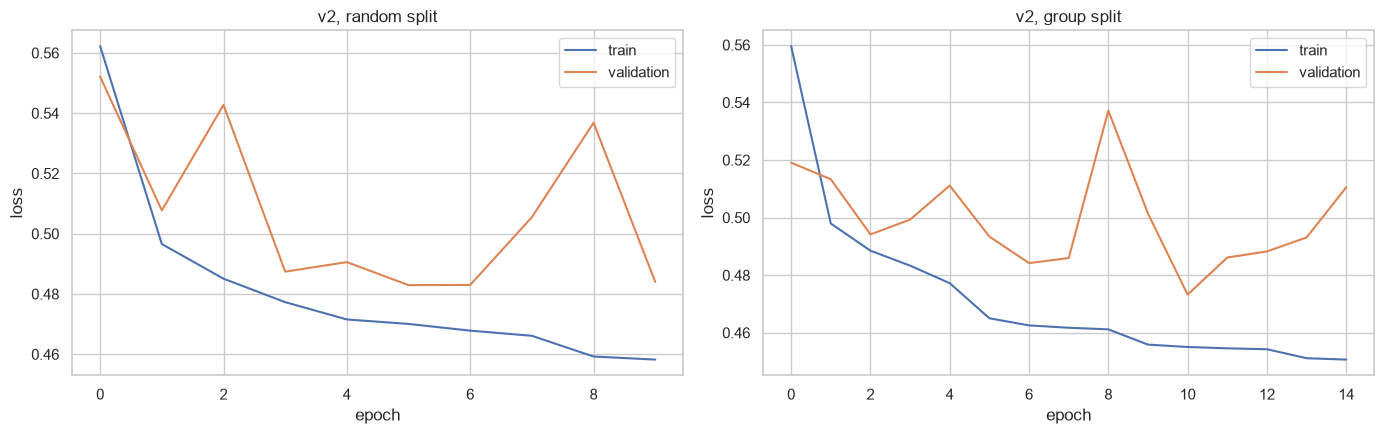

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, split in zip(axes, ["random", "group"]):
    path = REPORTS / f"hybrid_v2_history_{split}.json"
    if not path.exists():
        ax.set_title(f"{split}: not trained"); continue
    h = json.load(open(path))
    ax.plot(h["loss"], label="train"); ax.plot(h["val_loss"], label="validation")
    ax.set_title(f"v2, {split} split"); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend()
fig.tight_layout(); fig.savefig(FIGS / "hybrid_v2_training_curves.png", dpi=150); plt.show()

## Where the gain comes from
Per-class F1 of XGBoost, the v1 network and the v2 network on the group split.

In [6]:
xgb_pc = pd.read_csv(REPORTS / "baseline_per_class_f1.csv", index_col=0)["XGBoost (group)"]
v1_pc = pd.read_csv(REPORTS / "hybrid_per_class_f1.csv", index_col=0)["CNN-BiLSTM-Attention (group)"]
v2_pc = pd.read_csv(REPORTS / "hybrid_v2_per_class_f1.csv", index_col=0)["CNN-BiLSTM-Attention v2 (group)"]
per_class = pd.DataFrame({"XGBoost": xgb_pc, "network v1": v1_pc, "network v2": v2_pc}).loc[class_names]
per_class["v2 minus v1"] = per_class["network v2"] - per_class["network v1"]
per_class.round(3)

,XGBoost,network v1,network v2,v2 minus v1
BENIGN,1.000,0.984,0.999,0.015
DNS,0.687,0.574,0.622,0.048
LDAP,0.559,0.252,0.517,0.265
MSSQL,0.978,0.952,0.875,-0.077
NTP,0.996,0.982,0.989,0.007
NetBIOS,0.775,0.579,0.780,0.201
Portmap,0.415,0.320,0.327,0.007
SNMP,0.756,0.717,0.647,-0.070
SSDP,0.604,0.352,0.631,0.279
Syn,0.961,0.962,0.961,-0.001


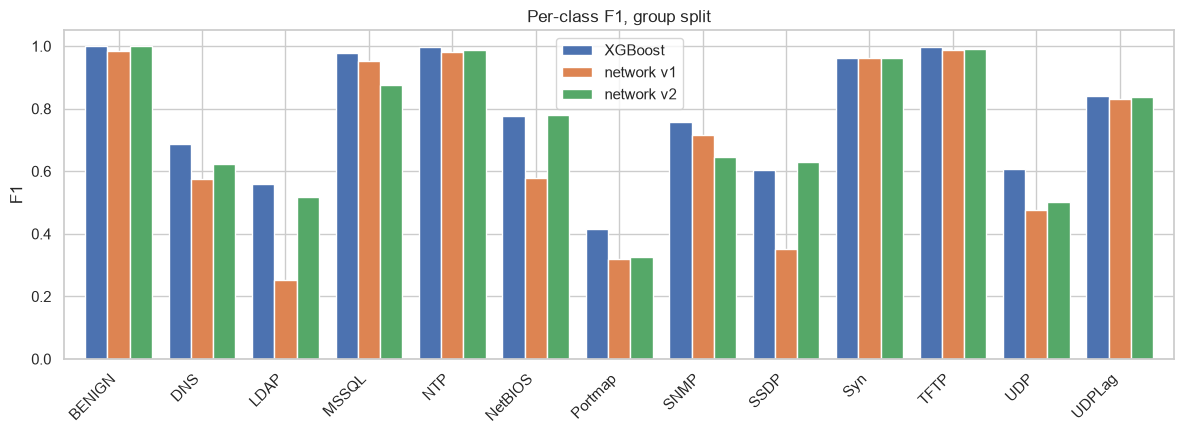

In [7]:
ax = per_class[["XGBoost", "network v1", "network v2"]].plot.bar(figsize=(12, 4.5), width=0.8)
ax.set_ylabel("F1"); ax.set_title("Per-class F1, group split"); plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.savefig(FIGS / "hybrid_v2_per_class_f1.png", dpi=150); plt.show()

## Confusion matrices

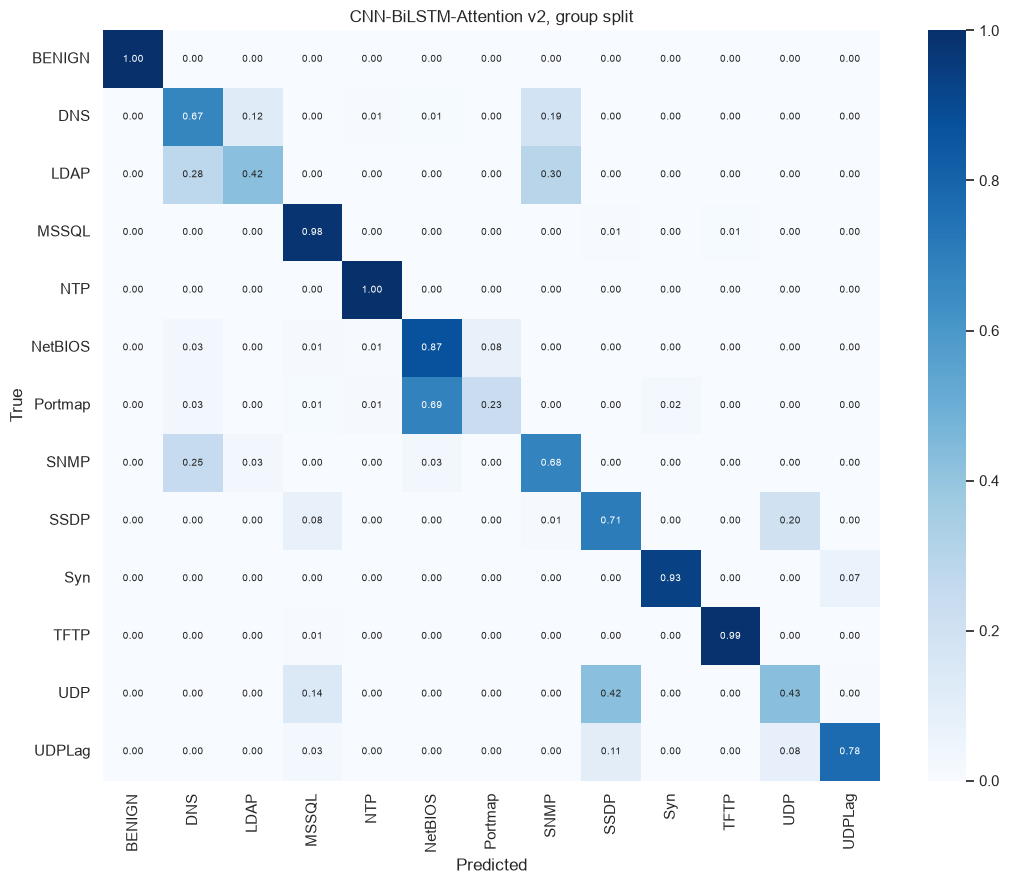

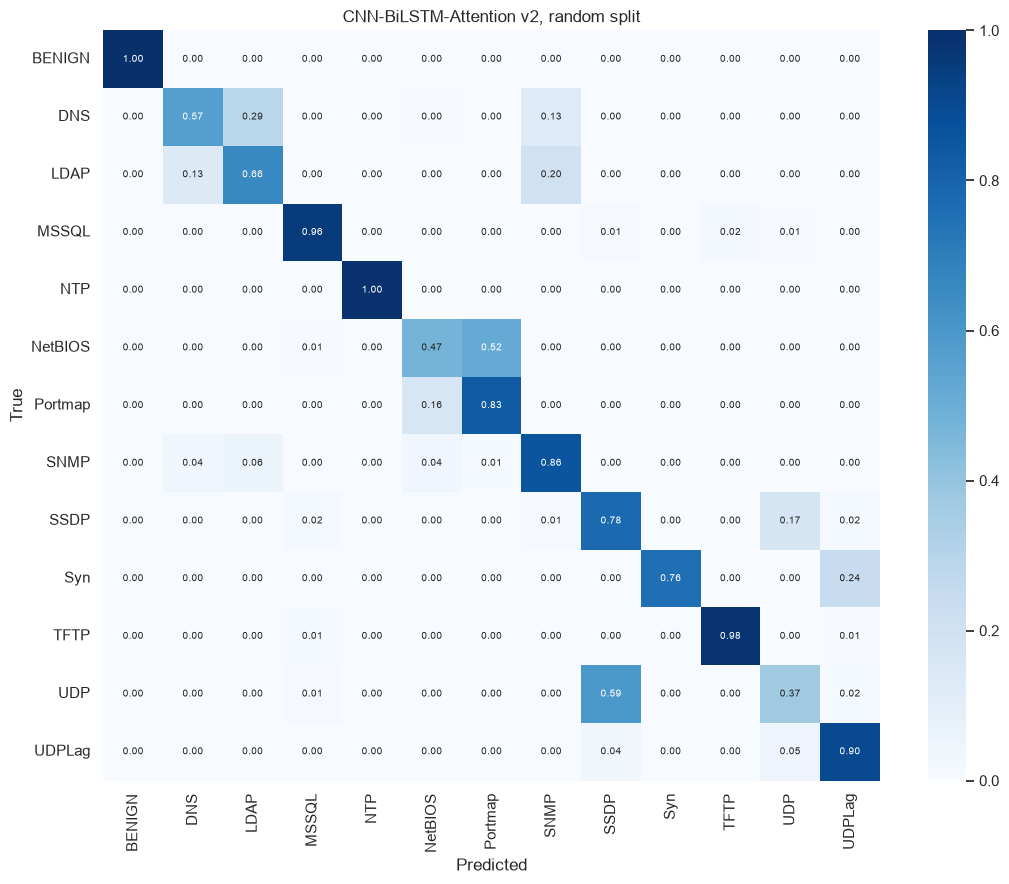

In [8]:
for split in ["group", "random"]:
    path = REPORTS / f"hybrid_v2_predictions_{split}.npy"
    if path.exists():
        y_true, y_pred = np.load(path).astype(int)
        plot_confusion(y_true, y_pred, class_names, f"CNN-BiLSTM-Attention v2, {split} split", FIGS / f"confusion_hybrid_v2_{split}.png")
        plt.show()